# Which wavelet bands does the camera frame rate change?

Proficient sessions are filmed at **60 Hz**; Pre-rec sessions (on the **same recording rig**), the earlier training
stages and the neuromodulator sessions at **30 Hz**. The left paw + wheel states cluster the 0.5–8 Hz Morlet amplitudes of 3.1.1 / 3.1.2, each band
z-scored within its session, so a pure per-band **gain** difference cancels. What could survive is an added
**noise floor** or a change in how bands co-vary. The measures are gain-invariant, per session and band:
`floor` = q10/q50 (a noise floor lifts the quiet frames), `peak` = q95/q50, `r_2hz` (coupling to the same
signal's 2 Hz band), `r_wheel` (left-paw x band vs the wheel's same band).

- **A. Decimation**: 30 proficient 60 Hz sessions, every other frame kept, through the pipeline's own
  `get_speed` + `fast_wavelet_morlet_convolution_parallel` (verified to reproduce the stored files exactly).
  Isolates *sampling*: aliasing, binning, dt rounding. Not the pose estimation (run on 60 Hz video).
- **B. Same mice, same rig, 30 vs 60 Hz**: stored wavelets of the 44 mice with both Pre-rec (recording rig, camera
  at 30 Hz) and Proficient (same rig, 60 Hz) sessions. Everything that comes with acquiring at 30 Hz (exposure,
  motion blur, pose estimated on 30 fps video), plus a few days of behaviour and the protocol.
  Baseline: two Pre-rec sessions of the same mouse (same setting, different days).

Code: `frame_rate_bands.py`; results cached in `data/frame_rate_bands/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import frame_rate_bands as fb
pd.set_option('display.width', 200)

In [2]:
#%%
""" A. DECIMATION 60 -> 30 Hz (medians over 30 sessions) """
A = fb.decimation_test(30)
key = [A['signal'], A['band']]
pd.DataFrame({'r(60, 30) frame-matched': A.groupby(key, sort=False)['r_60_30'].median(),
              'floor 30/60': (A['floor_30'] / A['floor_60']).groupby(key, sort=False).median(),
              'peak 30/60': (A['peak_30'] / A['peak_60']).groupby(key, sort=False).median(),
              'r_2hz 30-60': (A['r_2hz_30'] - A['r_2hz_60']).groupby(key, sort=False).median(),
              'r_wheel 30-60': (A['r_wheel_30'] - A['r_wheel_60']).groupby(key, sort=False).median()}).round(3)

r(60, 30) frame-matched  floor 30/60  peak 30/60  r_2hz 30-60  r_wheel 30-60
signal        band                                                                              
l_paw_x       0.5                     0.995        1.042       0.995       -0.000         -0.003
              1.0                     0.996        0.987       0.980        0.002         -0.002
              2.0                     0.997        0.974       0.965          NaN         -0.002
              4.0                     0.996        0.966       0.950        0.000          0.005
              8.0                     0.992        0.969       0.970        0.004          0.007
l_paw_y       0.5                     0.995        1.038       0.993       -0.001            NaN
              1.0                     0.996        0.995       0.982        0.002            NaN
              2.0                     0.997        0.974       0.964          NaN            NaN
              4.0                     0.996        0.965       0.944        0.001            NaN
              8.0                     0.991        0.961       0.956        0.005            NaN
avg_wheel_vel 0.5                     0.995        1.048       1.007       -0.001            NaN
              1.0                     0.997        1.023       0.980        0.001            NaN
              2.0                     0.997        1.036       0.965          NaN            NaN
              4.0                     0.997        1.064       0.980       -0.001            NaN
              8.0                     0.996        3.123       1.015       -0.001            NaN

Sampling alone changes nothing that matters: frame-matched r ≥ 0.99 in every band, floor / peak within
≈ 5 %, couplings unchanged. (The wheel's 8 Hz floor ratio is a ratio of two near-zero numbers: a still wheel
is exactly 0.)

In [3]:
#%%
""" B. SAME MICE, SAME RIG, 30 vs 60 Hz: medians of the mouse means, per camera setting """
B = fb.rate_test()
print(B.groupby('camera')['session'].nunique().to_dict(), f"{B['mouse'].nunique()} mice")
(B.groupby(['mouse', 'signal', 'band', 'camera'])[['floor', 'peak', 'r_wheel']].mean()
  .groupby(['signal', 'band', 'camera']).median().unstack('camera').round(3))

{'Pre-rec (30 Hz)': 117, 'Proficient (60 Hz)': 195} 44 mice


floor                               peak                            r_wheel                   
camera             Pre-rec (30 Hz) Proficient (60 Hz) Pre-rec (30 Hz) Proficient (60 Hz) Pre-rec (30 Hz) Proficient (60 Hz)
signal        band                                                                                                         
avg_wheel_vel 0.5            0.148              0.030           3.376              4.791             NaN                NaN
              1.0            0.066              0.013           3.951              6.222             NaN                NaN
              2.0            0.014              0.011           7.780             12.072             NaN                NaN
              4.0            0.000              0.004          17.055             27.519             NaN                NaN
              8.0            0.000              0.001          33.275             22.100             NaN                NaN
l_paw_x       0.5            0.191              0.058           3.376              4.660           0.343              0.496
              1.0            0.102              0.034           4.056              7.362           0.447              0.563
              2.0            0.056              0.046           7.372             15.257           0.539              0.624
              4.0            0.053              0.093          21.098             36.946           0.534              0.612
              8.0            0.088              0.153          43.715             60.246           0.400              0.428
l_paw_y       0.5            0.192              0.061           3.297              4.666             NaN                NaN
              1.0            0.116              0.038           3.875              6.771             NaN                NaN
              2.0            0.060              0.048           6.431             13.359             NaN                NaN
              4.0            0.055              0.091          19.261             32.981             NaN                NaN
              8.0            0.085              0.150          41.638             64.966             NaN                NaN

In [4]:
#%%
""" B. 60 - 30 Hz difference (per mouse) against the same-setting, day-to-day difference """
pd.concat([fb.rate_contrast(B, m) for m in ['floor', 'peak', 'r_2hz', 'r_wheel']]).round(3)

,signal,band,measure,n_mice,diff_60_30,frac_same_sign,p,abs_diff,same_setting_abs
0,avg_wheel_vel,0.5,floor,44,-0.105,0.818,0.000,0.105,0.050
1,avg_wheel_vel,1.0,floor,44,-0.054,0.682,0.000,0.054,0.020
2,avg_wheel_vel,2.0,floor,44,-0.001,0.545,0.168,0.019,0.006
3,avg_wheel_vel,4.0,floor,44,0.002,0.705,0.001,0.006,0.001
4,avg_wheel_vel,8.0,floor,44,0.001,0.727,0.018,0.003,0.000
5,l_paw_x,0.5,floor,44,-0.109,0.864,0.000,0.109,0.049
6,l_paw_x,1.0,floor,44,-0.060,0.886,0.000,0.060,0.050
7,l_paw_x,2.0,floor,44,-0.008,0.614,0.117,0.020,0.022
8,l_paw_x,4.0,floor,44,0.024,0.773,0.001,0.036,0.019
9,l_paw_x,8.0,floor,44,0.066,0.909,0.000,0.066,0.022


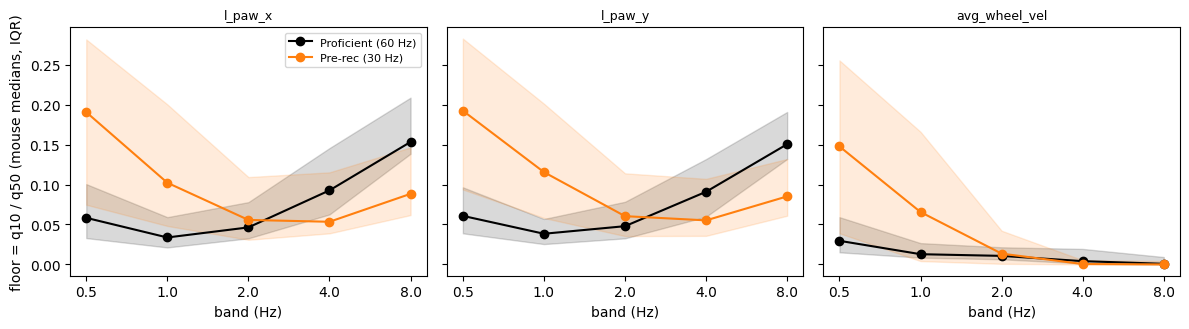

In [5]:
#%%
""" FIGURE: floor per band and camera setting, mouse means; paw vs wheel """
mm = B.groupby(['mouse', 'signal', 'band', 'camera'])['floor'].mean().reset_index()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, sig in zip(ax, fb.SIGNALS):
    for cam, c in [('Proficient (60 Hz)', 'k'), ('Pre-rec (30 Hz)', 'tab:orange')]:
        s = mm[(mm['signal'] == sig) & (mm['camera'] == cam)]
        med = s.groupby('band')['floor'].median()
        q = s.groupby('band')['floor'].quantile([.25, .75]).unstack()
        a.plot(range(len(med)), med.values, 'o-', color=c, label=cam)
        a.fill_between(range(len(med)), q[.25], q[.75], color=c, alpha=.15)
    a.set_xticks(range(len(fb.BANDS)), fb.BANDS); a.set_xlabel('band (Hz)'); a.set_title(sig, fontsize=9)
ax[0].set_ylabel('floor = q10 / q50 (mouse medians, IQR)'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Reading

1. **Frame rate as sampling is harmless** (A): decimating a 60 Hz session to 30 Hz leaves every band
   essentially unchanged. The aliasing prediction (a noise floor at 8 Hz on 30 Hz data) does **not** happen.
2. **Same rig, 30 vs 60 Hz acquisition: two separate effects** (B), both larger than the day-to-day difference:
   - **Slow bands, 0.5–1 Hz, paw AND wheel alike**: Pre-rec has a higher floor (≈ 0.19 vs 0.06) and a lower peak.
     The wheel is not filmed, so this is *not* the camera. It is behaviour or session structure: proficient
     (recording) sessions have deeper stillness and burstier movement than the biased Pre-rec sessions.
   - **Fast bands, 4–8 Hz, PAW ONLY**: the 60 Hz sessions have a higher floor (≈ 0.15 vs 0.09 at 8 Hz, 91 % of
     mice); the wheel's fast bands do not move. A camera / pose signature of the 60 Hz acquisition (more
     high-frequency paw jitter), and not sampling (A rules that out): it comes with the video itself
     (exposure, motion blur, pose estimated at a different frame rate). Same rig, so not rig hardware.
   - Paw–wheel coupling is higher in the 60 Hz sessions at the slow bands (+0.11 at 0.5 Hz), in line with
     `bwm-paw-wheel-xcorr-qc`.

**For the state space**: the 4–8 Hz paw floor is the acquisition signature that survives the per-session z-score.
A proficient-only fit would define states on 60 Hz data with that floor built in; 30 Hz data (Pre-rec, NM,
training) would sit "cleaner" at high bands.